# Netflix vs Amazon Prime: catalogue comparison 2022, 2023 and 2026

Covers README **Section 2 (content availability)** and **Section 3 (content quality)** for both services and all three snapshots, plus what was **added, removed and pulled back** between snapshots.

- Data loading and every mapping between the three sources live in `titles_loader.py`.
- Known data problems are listed in [`comparison_data_issues.md`](comparison_data_issues.md). Read it before quoting numbers.
- Snapshots: Netflix July 2022, Amazon May 2022, both March 2023, and the 2026 API export. Each source has a different scope, so **compare shares and patterns, not raw counts, across years.**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from titles_loader import load_titles, GENRES_OLD_ONLY, GENRES_2026_ONLY

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True})
SERVICES = ["Netflix", "Amazon"]
SNAPS = [2022, 2023, 2026]
SNAP_COLOR = {2022: "#9ecae1", 2023: "#4292c6", 2026: "#08306b"}
CHURN_COLOR = {"removed": "#d95f02", "kept": "#bdbdbd", "added": "#1b9e77"}

titles, coverage = load_titles()
titles["age"] = titles["snapshot"] - titles["release_year"]
coverage

raw_rows  after_dedupe  duplicates_dropped  no_imdb_id_%  \
service snapshot                                                             
Amazon  2022          9871          9868                   3           6.8   
        2023         10873         10873                   0           6.4   
        2026         10936         10933                   3           0.1   
Netflix 2022          5850          5848                   2           6.9   
        2023          6137          6134                   3           6.4   
        2026          7805          7803                   2           0.1   

                  imdb_score_%  countries_%  runtime_%  
service snapshot                                        
Amazon  2022              89.7         91.7      100.0  
        2023              89.8         93.8      100.0  
        2026              98.6          0.0       82.4  
Netflix 2022              91.8         96.1      100.0  
        2023              92.4         97.1      100.0  
        2026              99.4          0.0       56.6

**Coverage table above.** One row per service and snapshot: rows read, duplicates dropped, share of titles with no IMDb id, and how many have an IMDb score, a country list and a runtime. The 2026 export has **no countries** and many missing runtimes, so some charts below only cover 2022 and 2023.

---
# 1. Content availability
## 1.1 Catalogue size and movie/show mix

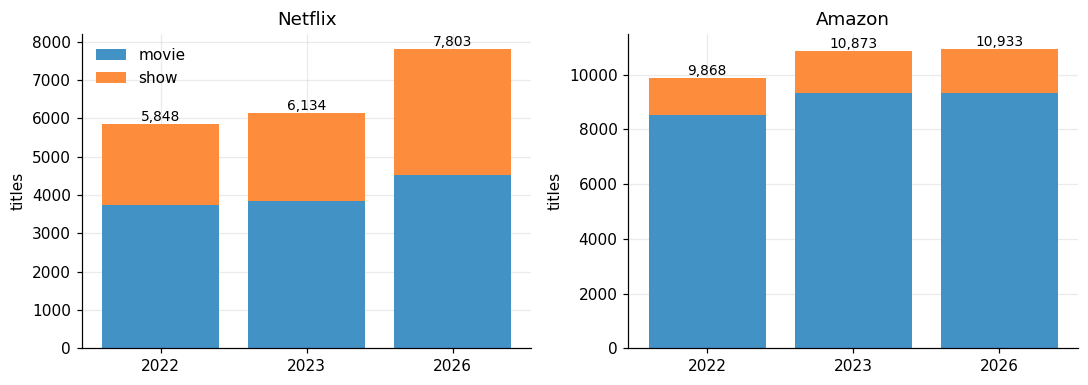

service,Amazon % shows,Netflix % shows
snapshot,,
2022,13.8,36.0
2023,14.3,37.5
2026,14.7,42.0


In [2]:
size = titles.groupby(["service", "snapshot", "type"]).size().unstack("type").fillna(0)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, s in zip(axes, SERVICES):
    d = size.loc[s]
    ax.bar(d.index.astype(str), d["movie"], color="#4292c6", label="movie")
    ax.bar(d.index.astype(str), d["show"], bottom=d["movie"], color="#fd8d3c", label="show")
    for x, tot in zip(d.index.astype(str), d.sum(axis=1)):
        ax.text(x, tot, f"{int(tot):,}", ha="center", va="bottom", fontsize=9)
    ax.set_title(s); ax.set_ylabel("titles")
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

(size["show"] / size.sum(axis=1)).unstack("service").mul(100).round(1).rename_axis("snapshot").add_suffix(" % shows")

## 1.2 Release-year distribution

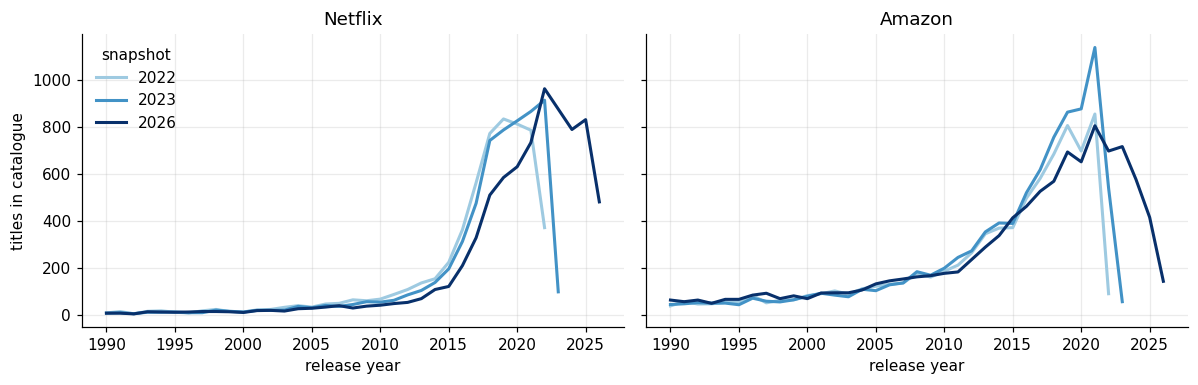

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, s in zip(axes, SERVICES):
    for y in SNAPS:
        c = titles[(titles.service == s) & (titles.snapshot == y) & (titles.release_year >= 1990)]
        c = c.groupby("release_year").size()
        ax.plot(c.index, c.values, color=SNAP_COLOR[y], label=str(y), lw=2)
    ax.set_title(s); ax.set_xlabel("release year")
axes[0].set_ylabel("titles in catalogue"); axes[0].legend(title="snapshot", frameon=False)
plt.tight_layout(); plt.show()

## 1.3 Recent versus older titles
Age = snapshot year minus release year. 2026 is a partial year, so its newest bucket is slightly understated.

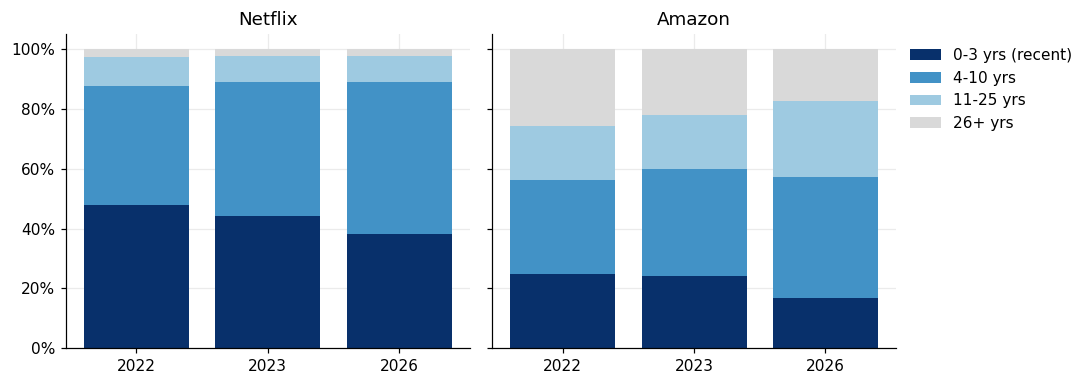

In [4]:
bins = [-1, 3, 10, 25, 200]; labels = ["0-3 yrs (recent)", "4-10 yrs", "11-25 yrs", "26+ yrs"]
titles["age_group"] = pd.cut(titles["age"], bins=bins, labels=labels)
ag = (titles.groupby(["service", "snapshot", "age_group"], observed=True).size()
      .unstack("age_group").pipe(lambda d: d.div(d.sum(axis=1), axis=0)))
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
pal = ["#08306b", "#4292c6", "#9ecae1", "#d9d9d9"]
for ax, s in zip(axes, SERVICES):
    d = ag.loc[s]; bottom = np.zeros(len(d))
    for lab, col in zip(labels, pal):
        ax.bar(d.index.astype(str), d[lab], bottom=bottom, color=col, label=lab)
        bottom += d[lab].values
    ax.set_title(s); ax.yaxis.set_major_formatter(PercentFormatter(1))
axes[1].legend(frameon=False, bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

## 1.4 Genres
Only genres that exist in **both** vocabularies are compared (see data-issues file). A title can have several genres, and 2026 titles carry fewer genre tags per title (about 1.8-2.0 against 2.1-2.6), so each bar is the **share of all genre tags** in that snapshot (each snapshot sums to 100%), not the share of titles.

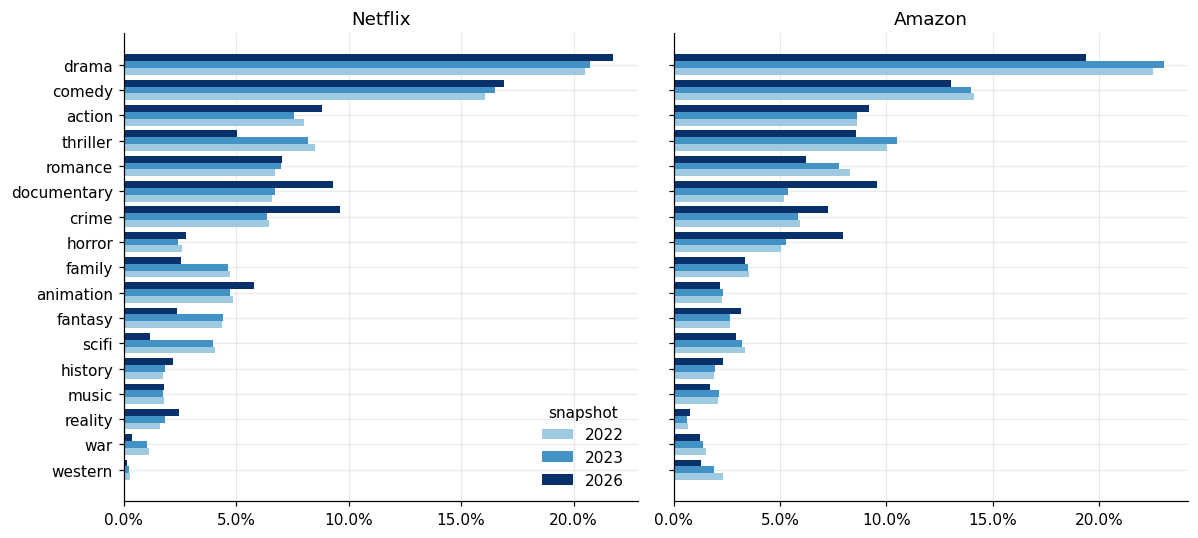

,Netflix (pp change 2022->2026),Amazon (pp change 2022->2026)
genre,,
thriller,-3.5,-1.5
scifi,-2.9,-0.4
family,-2.2,-0.2
fantasy,-2.0,0.5
war,-0.7,-0.3
western,-0.1,-1.0
music,-0.0,-0.4
horror,0.2,2.9
romance,0.3,-2.1


In [5]:
drop = GENRES_OLD_ONLY | GENRES_2026_ONLY
g = titles[["service", "snapshot", "genres"]].explode("genres").dropna(subset=["genres"])
g = g[~g.genres.isin(drop)]
cnt = g.groupby(["service", "snapshot", "genres"]).size().unstack(["service", "snapshot"]).fillna(0)
share = cnt / cnt.sum()   # share of all genre tags in that snapshot (2026 titles carry fewer tags per title)
order = share.mean(axis=1).sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)
h = .27
for ax, s in zip(axes, SERVICES):
    for i, y in enumerate(SNAPS):
        ax.barh(np.arange(len(order)) + (i - 1) * h, share.loc[order, (s, y)], height=h, color=SNAP_COLOR[y], label=str(y))
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_title(s)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(title="snapshot", frameon=False)
plt.tight_layout(); plt.show()

chg = pd.concat({s: (share[(s, 2026)] - share[(s, 2022)]) * 100 for s in SERVICES}, axis=1).round(1)
chg.sort_values("Netflix").rename_axis("genre").add_suffix(" (pp change 2022->2026)")

## 1.5 Countries of origin (2022 and 2023 only)
The 2026 export has no country data, so this section stops at 2023.

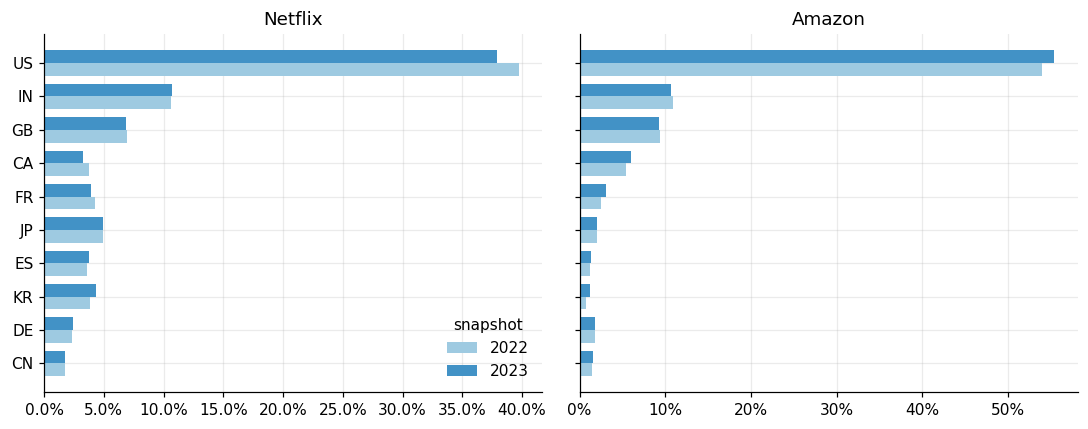

In [6]:
c = titles[titles.snapshot < 2026][["service", "snapshot", "countries"]].explode("countries").dropna(subset=["countries"])
n = titles[titles.snapshot < 2026].groupby(["service", "snapshot"]).size()
top = c.countries.value_counts().head(10).index[::-1]
cs = c.groupby(["service", "snapshot", "countries"]).size().unstack(["service", "snapshot"]).fillna(0).div(n, axis=1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
h = .38
for ax, s in zip(axes, SERVICES):
    for i, y in enumerate([2022, 2023]):
        ax.barh(np.arange(len(top)) + (i - .5) * h, cs.loc[top, (s, y)], height=h, color=SNAP_COLOR[y], label=str(y))
    ax.set_yticks(range(len(top))); ax.set_yticklabels(top); ax.set_title(s)
    ax.xaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(title="snapshot", frameon=False)
plt.tight_layout(); plt.show()

## 1.6 Summary: availability
**1.1 Size and mix (stacked bars + table).** Total titles per service and snapshot, split into movies and shows. *Useful because* catalogue size is the most direct measure of "how much do I get", and the show share tells whether the service is shifting toward series.

**1.2 Release-year lines.** Number of titles per release year, one line per snapshot. *Useful because* it shows where a catalogue grew or shrank: lines that drop below the earlier snapshot in older years mean back-catalogue titles disappeared, lines that rise at the right edge are new releases.

**1.3 Recent vs older (100% bars).** Share of the catalogue by age bucket. *Useful because* it separates "bigger catalogue" from "fresher catalogue", which is the licensing-versus-original-content question behind the enshittification argument.

**1.4 Genres (grouped bars + pp-change table).** Share of genre tags per genre and the percentage-point shift 2022 to 2026. *Useful because* it shows whether the mix is narrowing or tilting (for example toward reality or documentary), which a total count hides.

**1.5 Countries.** Top production countries per service in 2022 and 2023. *Useful because* it shows reliance on US content versus international content. Limited to 2022-2023 because 2026 has no country data.

---
# 2. Added, removed and pulled-back titles
Titles are matched across snapshots **within the same service** on IMDb id (title + year + type when there is no id).
**Removed** means "present in the earlier snapshot, absent in the later one". That is a *candidate* for being pulled, not proof: the two datasets may simply cover different things (see data-issues file).

In [7]:
keys = {(s, y): set(titles[(titles.service == s) & (titles.snapshot == y)].key) for s in SERVICES for y in SNAPS}
TRANS = [(2022, 2023), (2023, 2026), (2022, 2026)]
rows = []
for s in SERVICES:
    for a, b in TRANS:
        ka, kb = keys[(s, a)], keys[(s, b)]
        rows.append(dict(service=s, step=f"{a}->{b}", earlier=len(ka), later=len(kb),
                         removed=len(ka - kb), kept=len(ka & kb), added=len(kb - ka)))
churn = pd.DataFrame(rows)
churn["removed_%_of_earlier"] = (churn.removed / churn.earlier * 100).round(1)
churn["added_%_of_later"] = (churn.added / churn.later * 100).round(1)
churn

,service,step,earlier,later,removed,kept,added,removed_%_of_earlier,added_%_of_later
0,Netflix,2022->2023,5848,6134,1124,4724,1410,19.2,23.0
1,Netflix,2023->2026,6134,7803,2689,3445,4358,43.8,55.9
2,Netflix,2022->2026,5848,7803,2893,2955,4848,49.5,62.1
3,Amazon,2022->2023,9868,10873,2405,7463,3410,24.4,31.4
4,Amazon,2023->2026,10873,10933,8389,2484,8449,77.2,77.3
5,Amazon,2022->2026,9868,10933,7843,2025,8908,79.5,81.5


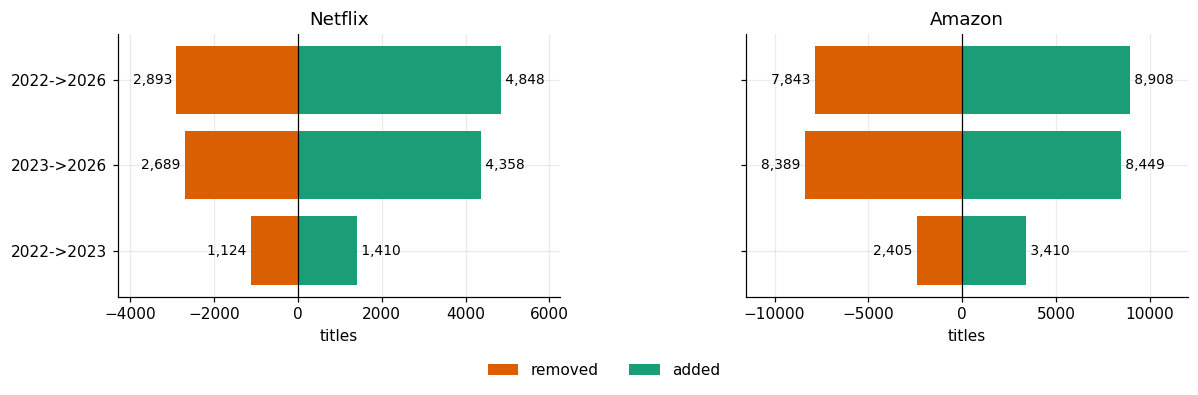

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, s in zip(axes, SERVICES):
    d = churn[churn.service == s].set_index("step")
    ax.barh(d.index, -d.removed, color=CHURN_COLOR["removed"], label="removed")
    ax.barh(d.index, d.added, color=CHURN_COLOR["added"], label="added")
    for i, (r, a_) in enumerate(zip(d.removed, d.added)):
        ax.text(-r, i, f"{r:,} ", ha="right", va="center", fontsize=9)
        ax.text(a_, i, f" {a_:,}", ha="left", va="center", fontsize=9)
    ax.axvline(0, color="k", lw=.8); ax.set_title(s); ax.set_xlabel("titles")
    ax.invert_yaxis(); ax.margins(x=.18)
axes[0].legend(frameon=False, loc="upper center", bbox_to_anchor=(1.1, -.2), ncol=2)
plt.tight_layout(); plt.show()

## 2.1 Who stays, who leaves, who comes back
Presence pattern across (2022, 2023, 2026): `1` = in the catalogue, `0` = not. For example `101` is a title that was there in 2022, missing in 2023 and back in 2026 (**pulled and returned**).

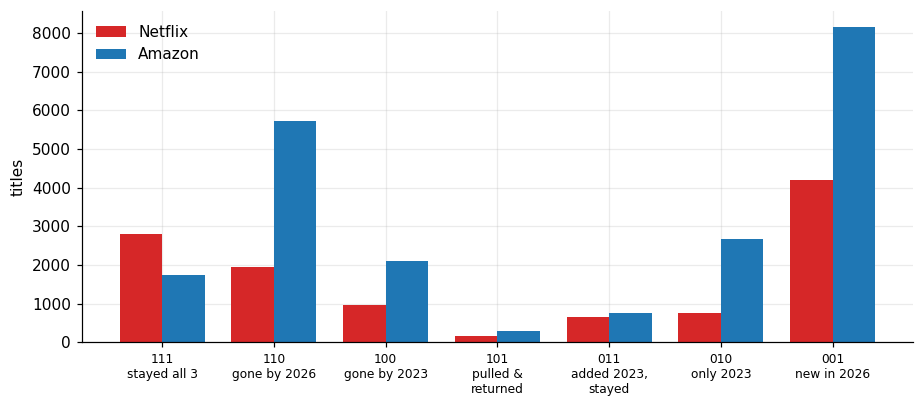

service,Amazon,Netflix
pattern,,
stayed all 3,1734,2789
gone by 2026,5729,1935
gone by 2023,2114,958
pulled & returned,291,166
"added 2023, stayed",750,656
only 2023,2660,754
new in 2026,8158,4192


In [9]:
pat_rows = []
for s in SERVICES:
    allk = keys[(s, 2022)] | keys[(s, 2023)] | keys[(s, 2026)]
    for k in allk:
        pat_rows.append((s, "".join("1" if k in keys[(s, y)] else "0" for y in SNAPS), k))
pat = pd.DataFrame(pat_rows, columns=["service", "pattern", "key"])
names = {"111": "stayed all 3", "110": "gone by 2026", "100": "gone by 2023", "101": "pulled & returned",
         "011": "added 2023, stayed", "010": "only 2023", "001": "new in 2026"}
pc = pat.groupby(["service", "pattern"]).size().unstack("service").reindex(list(names)).fillna(0).astype(int)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(len(pc)); w = .38
for i, s in enumerate(SERVICES):
    ax.bar(x + (i - .5) * w, pc[s], width=w, label=s, color=["#d62728", "#1f77b4"][i])
ax.set_xticks(x); ax.set_xticklabels([f"{p}\n{names[p].replace(' & ', ' &\n').replace(', ', ',\n')}" for p in pc.index], fontsize=8)
ax.set_ylabel("titles"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
pc.rename(index=names)

## 2.2 New releases or back catalogue?
For titles **added** between two snapshots: released since the earlier snapshot year (new releases) or older (back-catalogue additions, e.g. licensing deals).

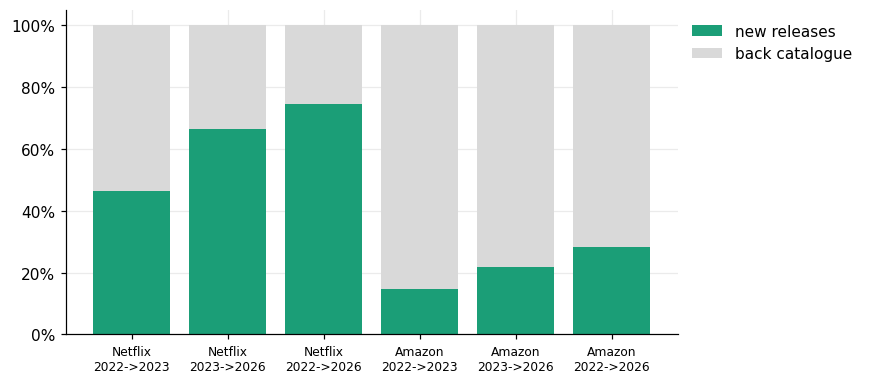

,service,step,added,new_release_share
0,Netflix,2022->2023,1410,46.2
1,Netflix,2023->2026,4358,66.4
2,Netflix,2022->2026,4848,74.7
3,Amazon,2022->2023,3410,14.8
4,Amazon,2023->2026,8449,21.6
5,Amazon,2022->2026,8908,28.3


In [10]:
add_rows = []
for s in SERVICES:
    for a, b in TRANS:
        added = titles[(titles.service == s) & (titles.snapshot == b) & titles.key.isin(keys[(s, b)] - keys[(s, a)])]
        new = (added.release_year >= a).mean()
        add_rows.append(dict(service=s, step=f"{a}->{b}", added=len(added), new_release_share=new))
addf = pd.DataFrame(add_rows)
fig, ax = plt.subplots(figsize=(8, 3.6))
lab = addf.service + "\n" + addf.step
ax.bar(lab, addf.new_release_share, color="#1b9e77", label="new releases")
ax.bar(lab, 1 - addf.new_release_share, bottom=addf.new_release_share, color="#d9d9d9", label="back catalogue")
ax.yaxis.set_major_formatter(PercentFormatter(1)); ax.legend(frameon=False, bbox_to_anchor=(1, 1))
plt.xticks(fontsize=8); plt.tight_layout(); plt.show()
addf.assign(new_release_share=(addf.new_release_share * 100).round(1))

## 2.3 Does the churn raise or lower quality?
IMDb mean and share rated 7+ among **removed**, **kept** and **added** titles for each step (rated titles only; scores come from the later snapshot for added/kept and the earlier snapshot for removed).

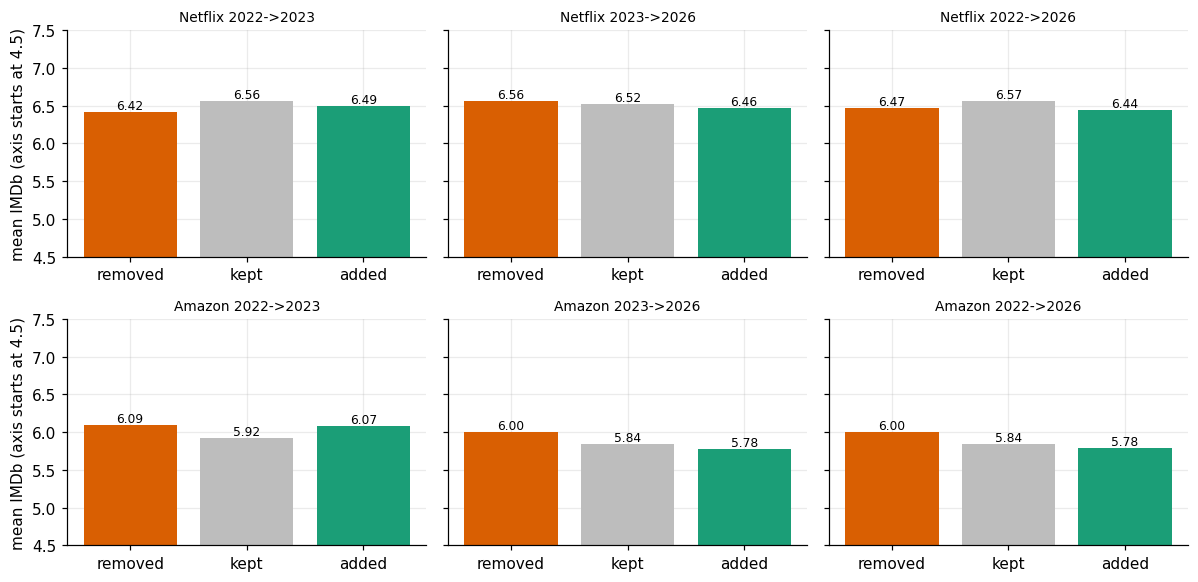

n_rated                 mean_imdb                 \
group                added    kept removed     added   kept removed   
service step                                                          
Amazon  2022->2023  3071.0  6694.0  2230.0     6.075  5.923   6.088   
        2022->2026  8766.0  2017.0  6854.0     5.784  5.840   6.003   
        2023->2026  8311.0  2472.0  7322.0     5.781  5.842   5.995   
Netflix 2022->2023  1305.0  4364.0  1023.0     6.491  6.556   6.418   
        2022->2026  4804.0  2949.0  2437.0     6.441  6.567   6.466   
        2023->2026  4315.0  3438.0  2249.0     6.465  6.519   6.555   

                   share_7plus                 
group                    added   kept removed  
service step                                   
Amazon  2022->2023       0.287  0.239   0.257  
        2022->2026       0.220  0.215   0.254  
        2023->2026       0.218  0.225   0.258  
Netflix 2022->2023       0.370  0.395   0.368  
        2022->2026       0.345  0.388   0.384  
        2023->2026       0.354  0.371   0.407

In [11]:
q_rows = []
for s in SERVICES:
    for a, b in TRANS:
        ta = titles[(titles.service == s) & (titles.snapshot == a)].set_index("key")
        tb = titles[(titles.service == s) & (titles.snapshot == b)].set_index("key")
        groups = {"removed": ta.loc[list(keys[(s, a)] - keys[(s, b)])],
                  "kept": tb.loc[list(keys[(s, a)] & keys[(s, b)])],
                  "added": tb.loc[list(keys[(s, b)] - keys[(s, a)])]}
        for gname, d in groups.items():
            r = d.imdb_score.dropna()
            q_rows.append(dict(service=s, step=f"{a}->{b}", group=gname, n_rated=len(r),
                               mean_imdb=r.mean(), share_7plus=(r >= 7).mean()))
qchurn = pd.DataFrame(q_rows)
fig, axes = plt.subplots(2, 3, figsize=(11, 5.4), sharey="row")
for j, (a, b) in enumerate(TRANS):
    for i, s in enumerate(SERVICES):
        d = qchurn[(qchurn.service == s) & (qchurn.step == f"{a}->{b}")].set_index("group").loc[["removed", "kept", "added"]]
        axes[i, j].bar(d.index, d.mean_imdb, color=[CHURN_COLOR[x] for x in d.index])
        for k, v in enumerate(d.mean_imdb):
            axes[i, j].text(k, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
        axes[i, j].set_ylim(4.5, 7.5)
        axes[i, j].set_title(f"{s} {a}->{b}", fontsize=9)
axes[0, 0].set_ylabel("mean IMDb (axis starts at 4.5)"); axes[1, 0].set_ylabel("mean IMDb (axis starts at 4.5)")
plt.tight_layout(); plt.show()
qchurn.round(3).pivot(index=["service", "step"], columns="group", values=["n_rated", "mean_imdb", "share_7plus"]).round(3)

## 2.4 The most-voted titles that left
Titles in the 2022 catalogue that are **not** in the 2026 catalogue, ranked by IMDb votes. These are the clearest candidates for "pulled back" but must be checked by hand before being cited.

In [12]:
for s in SERVICES:
    gone = titles[(titles.service == s) & (titles.snapshot == 2022) & titles.key.isin(keys[(s, 2022)] - keys[(s, 2026)])]
    print(s, f"- {len(gone):,} titles from 2022 not in 2026")
    display(gone.nlargest(10, "imdb_votes")[["title", "type", "release_year", "imdb_score", "imdb_votes"]]
            .assign(imdb_votes=lambda d: d.imdb_votes.astype(int)).reset_index(drop=True))

Netflix - 2,893 titles from 2022 not in 2026


,title,type,release_year,imdb_score,imdb_votes
0,Inception,movie,2010,8.8,2294231
1,Forrest Gump,movie,1994,8.8,2021343
2,The Dark Knight Rises,movie,2012,8.4,1669067
3,Se7en,movie,1995,8.6,1606270
4,Django Unchained,movie,2012,8.4,1472668
5,The Departed,movie,2006,8.5,1296244
6,Titanic,movie,1997,7.9,1146825
7,Léon: The Professional,movie,1994,8.5,1137357
8,GoodFellas,movie,1990,8.7,1131681
9,Catch Me If You Can,movie,2002,8.1,952602


Amazon - 7,843 titles from 2022 not in 2026


,title,type,release_year,imdb_score,imdb_votes
0,Titanic,movie,1997,7.9,1133692
1,The Usual Suspects,movie,1995,8.5,1059480
2,Braveheart,movie,1995,8.4,1016629
3,The Sixth Sense,movie,1999,8.2,967864
4,The Terminator,movie,1984,8.1,841706
5,Dexter,show,2006,8.7,711566
6,Skyfall,movie,2012,7.8,684779
7,District 9,movie,2009,7.9,670344
8,Arrival,movie,2016,7.9,669220
9,How I Met Your Mother,show,2005,8.3,661972


## 2.5 Summary: churn
**Added/removed bars + table.** For each step, how many titles left (orange, left) and arrived (green, right). *Useful because* a stable-looking total can hide heavy turnover; the removed share of the earlier catalogue is the headline measure of churn.

**Presence patterns.** Titles grouped by in/out status over the three snapshots. *Useful because* it separates titles that simply stayed from those removed permanently and those pulled and later returned (licence expiry and renewal).

**New releases vs back catalogue.** Of the added titles, how many are genuinely new. *Useful because* it shows whether growth comes from fresh releases or from licensed older titles.

**Quality of removed/kept/added.** Mean IMDb by group. *Useful because* it answers whether the titles lost were better or worse than the titles gained, i.e. whether churn lowers or raises the catalogue's quality.

**Most-voted titles gone.** A concrete list of well-known titles that left. *Useful because* popular titles are what subscribers notice, so they matter more than the raw count.

---
# 3. Content quality
Only titles with an IMDb score are used (about 90% in 2022-2023 and 99% in 2026, see coverage table), so quality figures describe the **rated** part of each catalogue.
## 3.1 Mean, median and share rated 7+

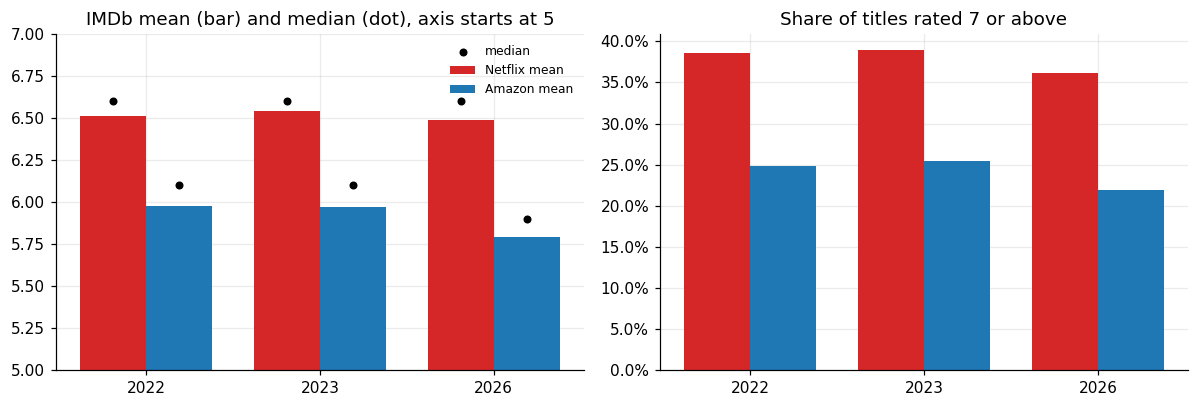

mean  median  share_7plus      n
service snapshot                                   
Amazon  2022      5.977     6.1        0.249   8847
        2023      5.971     6.1        0.254   9765
        2026      5.795     5.9        0.219  10783
Netflix 2022      6.511     6.6        0.386   5368
        2023      6.541     6.6        0.389   5669
        2026      6.489     6.6        0.362   7753

In [13]:
rated = titles.dropna(subset=["imdb_score"])
qs = rated.groupby(["service", "snapshot"]).imdb_score.agg(mean="mean", median="median",
        share_7plus=lambda s: (s >= 7).mean(), n="size")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(3); w = .38
for i, s in enumerate(SERVICES):
    d = qs.loc[s]
    axes[0].bar(x + (i - .5) * w, d["mean"], width=w, color=["#d62728", "#1f77b4"][i], label=f"{s} mean")
    axes[0].scatter(x + (i - .5) * w, d["median"], color="k", zorder=3, s=18, label="median" if i == 0 else None)
    axes[1].bar(x + (i - .5) * w, d["share_7plus"], width=w, color=["#d62728", "#1f77b4"][i], label=s)
for ax in axes:
    ax.set_xticks(x); ax.set_xticklabels(SNAPS)
axes[0].set_ylim(5, 7); axes[0].set_title("IMDb mean (bar) and median (dot), axis starts at 5"); axes[0].legend(frameon=False, fontsize=8)
axes[1].set_title("Share of titles rated 7 or above"); axes[1].yaxis.set_major_formatter(PercentFormatter(1))
plt.tight_layout(); plt.show()
qs.round(3)

## 3.2 IMDb vote counts
Votes are a proxy for audience attention. Shown on a log scale because a few titles have millions of votes.

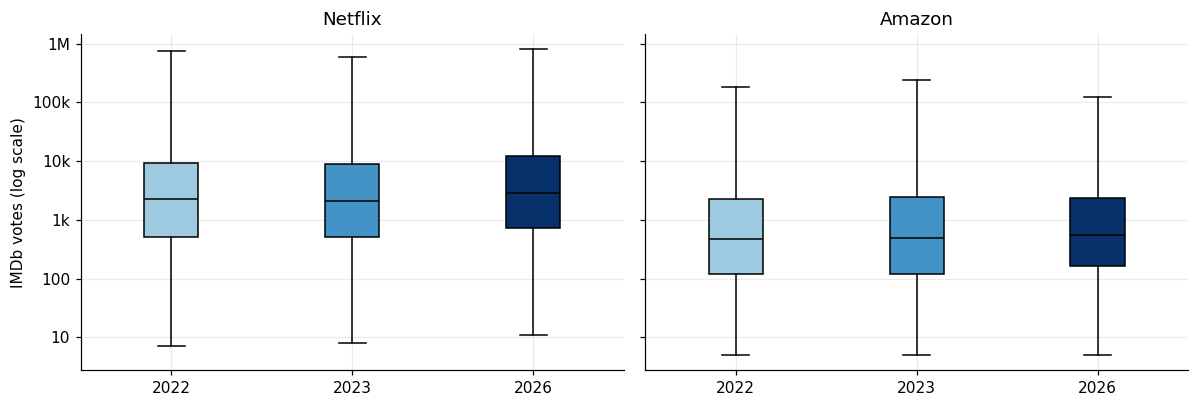

median  share_ge_1k  share_ge_10k
service snapshot                                   
Amazon  2022       464.0        0.365         0.106
        2023       488.0        0.379         0.114
        2026       556.0        0.385         0.102
Netflix 2022      2233.5        0.643         0.244
        2023      2095.0        0.638         0.234
        2026      2850.0        0.695         0.273

In [14]:
v = rated.dropna(subset=["imdb_votes"]).copy(); v = v[v.imdb_votes > 0]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, s in zip(axes, SERVICES):
    data = [np.log10(v[(v.service == s) & (v.snapshot == y)].imdb_votes) for y in SNAPS]
    bp = ax.boxplot(data, labels=SNAPS, showfliers=False, patch_artist=True, medianprops=dict(color="k"))
    for patch, y in zip(bp["boxes"], SNAPS): patch.set_facecolor(SNAP_COLOR[y])
    ax.set_title(s); ax.set_yticks([1, 2, 3, 4, 5, 6]); ax.set_yticklabels(["10", "100", "1k", "10k", "100k", "1M"])
axes[0].set_ylabel("IMDb votes (log scale)")
plt.tight_layout(); plt.show()
vs = v.groupby(["service", "snapshot"]).imdb_votes.agg(median="median", share_ge_1k=lambda s: (s >= 1000).mean(),
                                                       share_ge_10k=lambda s: (s >= 10000).mean())
vs.round(3)

## 3.3 Quality of recent versus older titles

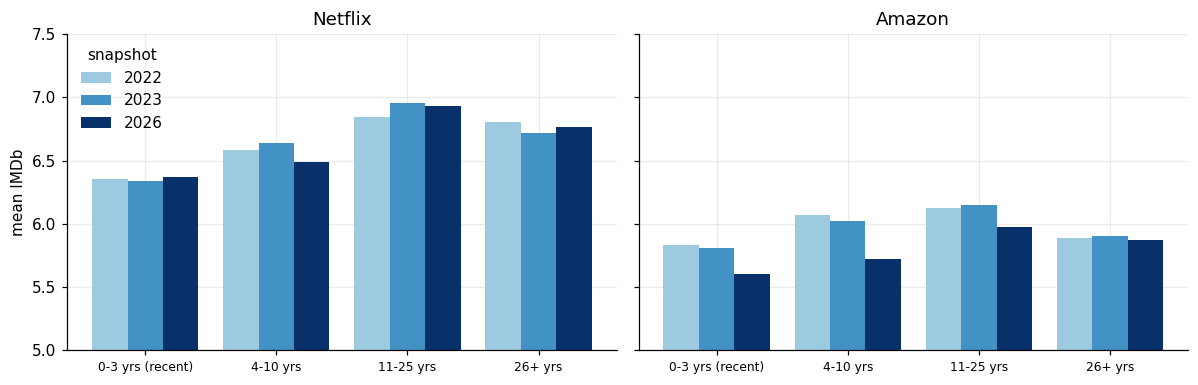

age_group         0-3 yrs (recent)  4-10 yrs  11-25 yrs  26+ yrs
service snapshot                                                
Amazon  2022                  5.84      6.07       6.12     5.89
        2023                  5.81      6.02       6.15     5.91
        2026                  5.60      5.72       5.98     5.87
Netflix 2022                  6.36      6.58       6.84     6.81
        2023                  6.34      6.64       6.95     6.72
        2026                  6.37      6.49       6.93     6.77

In [15]:
ra = rated.groupby(["service", "snapshot", "age_group"], observed=True).imdb_score.mean().unstack("age_group")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
x = np.arange(len(labels)); w = .27
for ax, s in zip(axes, SERVICES):
    for i, y in enumerate(SNAPS):
        ax.bar(x + (i - 1) * w, ra.loc[(s, y), labels], width=w, color=SNAP_COLOR[y], label=str(y))
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8); ax.set_title(s); ax.set_ylim(5, 7.5)
axes[0].set_ylabel("mean IMDb"); axes[0].legend(title="snapshot", frameon=False)
plt.tight_layout(); plt.show()
ra.round(2)

## 3.4 Same titles, different year: does IMDb change?
For titles present in both snapshots with a score in both. Differences mix real rating drift with the fact that the two sources scraped IMDb on different dates.

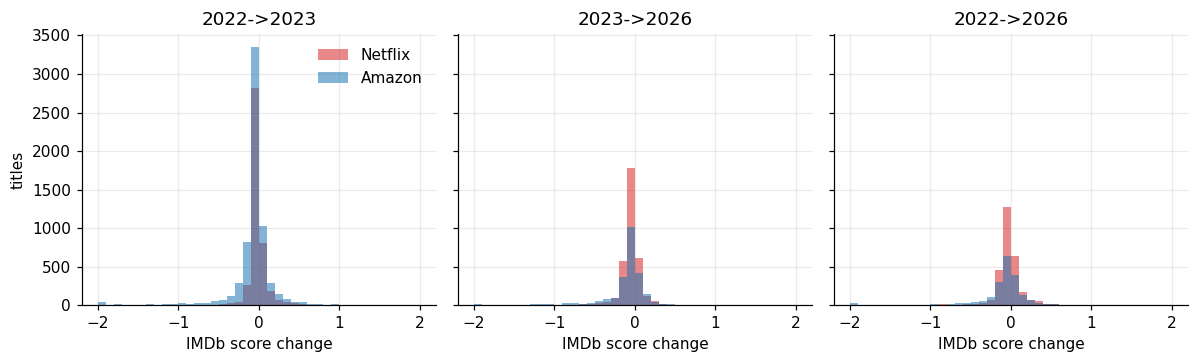

n   mean  median  share_unchanged
service step                                            
Amazon  2022->2023  6617 -0.023     0.0            0.506
        2022->2026  1992 -0.050     0.0            0.317
        2023->2026  2442 -0.059     0.0            0.413
Netflix 2022->2023  4345  0.023     0.0            0.647
        2022->2026  2926  0.018     0.0            0.435
        2023->2026  3414 -0.012     0.0            0.520

In [16]:
dr = []
for s in SERVICES:
    for a, b in [(2022, 2023), (2023, 2026), (2022, 2026)]:
        ta = rated[(rated.service == s) & (rated.snapshot == a)].set_index("key")
        tb = rated[(rated.service == s) & (rated.snapshot == b)].set_index("key")
        both = ta.index.intersection(tb.index)
        d = (tb.loc[both, "imdb_score"] - ta.loc[both, "imdb_score"])
        dr.append(pd.DataFrame(dict(service=s, step=f"{a}->{b}", delta=d.values)))
dr = pd.concat(dr)
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, step in zip(axes, [f"{a}->{b}" for a, b in [(2022, 2023), (2023, 2026), (2022, 2026)]]):
    for s, col in zip(SERVICES, ["#d62728", "#1f77b4"]):
        ax.hist(dr[(dr.service == s) & (dr.step == step)].delta.clip(-2, 2), bins=np.arange(-2, 2.05, .1),
                alpha=.55, color=col, label=s)
    ax.set_title(step); ax.set_xlabel("IMDb score change")
axes[0].set_ylabel("titles"); axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()
dr.groupby(["service", "step"]).delta.agg(n="size", mean="mean", median="median", share_unchanged=lambda s: (s == 0).mean()).round(3)

## 3.5 Summary: quality
**Mean/median and 7+ share.** Average rated quality and the share of well-rated titles. *Useful because* these are the simplest signals of whether the catalogue got better or worse, and both mean and share are shown since a mean can hide a shift at the top.

**Vote-count boxes.** Spread of IMDb votes per snapshot. *Useful because* it shows how much of each catalogue people actually rate: a catalogue padded with obscure titles has a low median. Note that older snapshots naturally accumulate fewer votes.

**Recent vs older quality.** Mean IMDb by age bucket. *Useful because* it checks whether new additions are as well rated as older titles; falling quality in the recent bucket is a classic enshittification pattern.

**Same-title score change.** Distribution of score differences for titles in both snapshots. *Useful because* it shows how much of any quality change is just rating drift on the same titles, versus a change in which titles are offered.

---
# 4. Key numbers

In [17]:
key = coverage[["after_dedupe"]].rename(columns={"after_dedupe": "titles"}).join(
    qs[["mean", "median", "share_7plus"]]).join(
    titles.groupby(["service", "snapshot"]).age.apply(lambda a: (a <= 3).mean()).rename("share_recent_0_3yrs"))
key.round(3)

titles   mean  median  share_7plus  share_recent_0_3yrs
service snapshot                                                         
Amazon  2022        9868  5.977     6.1        0.249                0.248
        2023       10873  5.971     6.1        0.254                0.240
        2026       10933  5.795     5.9        0.219                0.169
Netflix 2022        5848  6.511     6.6        0.386                0.480
        2023        6134  6.541     6.6        0.389                0.441
        2026        7803  6.489     6.6        0.362                0.382